In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
  #  for filename in filenames:
    #
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp
import warnings

<h1>Part 1 Description and Data</h1>
This project aims to predict housing prices using machine learning techniques. 
We are given 79 variables describing the aspects of residential homes in Ames, Iowa.
The training dataset has 1460 datapoints and the test set has 1459.

Read in the test and training data

In [ ]:
testdf = pd.read_csv('/kaggle/input/house-prices-advanced-regression-techniques/test.csv')
traindf = pd.read_csv('/kaggle/input/house-prices-advanced-regression-techniques/train.csv')
testdf_Id=testdf['Id']

<h1>Data</h1>

Just printing out the first 10 records of the training data. We can see some features that are recognizable to us like LotArea and YearSold. We will do a deeper dive into the data in the next section.

In [ ]:
print(traindf.head(10))

In [ ]:
traindf.info()

In [ ]:
print(traindf.shape)
print(testdf.shape)

In [ ]:
testdf.columns == traindf.columns[:-1]

In [ ]:
traindf.dtypes.value_counts()

Check the percentage of null values for variables that have null values.

In [ ]:
nullCountTrainDF=traindf.isnull().sum()
#nullCountTestDF=testdf.isnull().sum()
print(nullCountTrainDF[nullCountTrainDF>0]/1460)
#print(nullCountTestDF[nullCountTestDF>0]/1459)

<h1>Part 2 Exploratory Data Analysis</h1>
So far we have just taken a look at the data and the structure. The training data consists of 1460 records, while the test data consist of 1459 records. There are 79 variables that describe the homes.
We have found that there are some features with a high percentage of missing data. Any feature with over 10% missing data can be removed.

In [ ]:
print(nullCountTrainDF[nullCountTrainDF/1460>0.1])

In [ ]:
# Drop specified columns from df
testdf = testdf.drop(columns=['LotFrontage','MasVnrType','FireplaceQu','PoolQC', 'MiscFeature', 'Fence', 'Alley'])
traindf = traindf.drop(columns=['LotFrontage','MasVnrType','FireplaceQu','PoolQC', 'MiscFeature', 'Fence', 'Alley'])

In [ ]:
print(traindf.head(10))
print(testdf.head(10))

The new training set has 72 features. 7 were removed due to having too many null values.
Let's visualize the distribution of the numerical data values.

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline
traindf.select_dtypes(include=['float64','int64'])
n_features1 = 10
n_rows = 13
num_df = traindf.select_dtypes(include=['float64','int64'])
fig, axs = plt.subplots(n_rows,3, figsize = (20,60))
fig.subplots_adjust(hspace=.8, wspace=.3)
for k in axs:
    for i,j in zip(num_df, axs.flat):
        g = num_df[i].plot.kde(ax = j, title = i)
        g.get_xaxis().tick_bottom()
        g.get_yaxis().tick_left()

The distribution doesn't look too abnormal. For the most part, they are somewhat normally with some skew. There are also some bimodal and multimodal distribution curves. 

Let's visualize the distribution of the categorical data

In [ ]:
import seaborn as sns
#object features
object_features = traindf.dtypes[traindf.dtypes == 'object'].index
n_features1 = 10
n_rows = 13
object_df = traindf[object_features]

fig, axs = plt.subplots(n_rows,3, figsize = (20,60))

fig.subplots_adjust(hspace=.8, wspace=.3)


for k in axs:
    for i,j in zip(object_features, axs.flat):
        g = sns.countplot(x=i, data=object_df, ax=j)
        plt.setp(j.get_xticklabels(), rotation=90)

Let's take a look at the correlation matrix just see if there is any collinearity.

In [ ]:
correlation_matrix = traindf.corr(numeric_only=True)

In [ ]:
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of traindf')
plt.show()

Show pairs that have a 0.7+ correlation with each other.

In [ ]:
correlation_pairs = correlation_matrix.unstack()
high_corr_pairs = correlation_pairs[abs(correlation_pairs) > 0.7]
filtered_pairs = high_corr_pairs[high_corr_pairs.index.get_level_values(0) != high_corr_pairs.index.get_level_values(1)]
print("Pairs with correlation above 0.7:")
print(filtered_pairs)

We can see that there are several features pairs that are linearly correlated. We can remove some of these features to reduce multi-collinearity. 

In [ ]:
mc_columns = ['Id','TotalBsmtSF', 'GarageYrBlt','TotRmsAbvGrd','GarageCars']
traindf.drop(mc_columns, axis = 1, inplace = True)
testdf.drop(mc_columns, axis = 1, inplace = True)

In [ ]:
train_x = traindf.drop('SalePrice', axis=1)
train_y = traindf[['SalePrice']]
print(train_x.shape)
print(testdf.shape)

Now, we are down to 67 features

In [ ]:
cat_cols = train_x.select_dtypes(include='object').columns
for col in cat_cols:
    print(f"\nUnique values in '{col}':")
    print(train_x[col].value_counts())
    print(testdf[col].value_counts())

Convert categories to car codes so it will work in the model

In [ ]:
num_train_rows=train_x.shape[0]
num_test_rows=testdf.shape[0]
result_df = pd.concat([train_x, testdf], axis=0, ignore_index=True)
for col in cat_cols:
    result_df[col] = result_df[col].astype('category').cat.codes
train_x=result_df[:num_train_rows]
testdf=result_df[num_train_rows:]

In [ ]:
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error as mse

Split the training data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(train_x, train_y, test_size=0.2, random_state=42)


<h1>Part 3 Model</h1>

XGBoost is suitable for housing price predictions because it handles tabular data well. Nonlinear price relationships can also be handled by XGBoost. XGBoost also have built-in regularization to prevent overfitting. We handled collinearity by removing collinear pairs in the previous section.
<h2>HyperParameter Optimization Procedure:</h2>
We define the grid search setup using 3 different values and 5 hyperparameters, leading to 243 possible hyperparameter combinations. We will perform k-fold cross-validation (5 by default) to estimate generalization performance. We will use neg_mean_squared_error(minimizing MSE) as our scoring metric and the best parameters will be chosen based on CV performance.
Based on the XGBoost Documentation, the most important parameters to tune are the following:
https://xgboosting.com/most-important-xgboost-hyperparameters-to-tune/
Max_depth, min_child_weight, subsample, colsample_bytree, learning_rate

In [ ]:
import xgboost
from sklearn.model_selection import GridSearchCV
#for tuning parameters
parameters_tune = {
    'max_depth': [3, 5, 7],
    'min_child_weight': [1, 3, 5],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'learning_rate': [0.01, 0.1, 0.3]
}
                
xgb_model = xgboost.XGBRegressor(n_estimators=100, gamma=0,random_state=42)

grid_search = GridSearchCV(estimator = xgb_model, param_grid = parameters_tune, n_jobs=6, verbose=2,scoring='neg_mean_squared_error')
grid_search.fit(X_train, y_train)
# Print best parameters
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best score: {grid_search.best_score_}")

<h1>Part 4 Results and Discussion</h1>

The negative mean squared error of the best model is -688821169.645248. Taking the squareroot of the absolute value of this gives us $26245.40, which is the average magnitude of errors in a model's predictions.
The mean Saleprice of a home is $180,921.20, calculated below. We can also see that there are some home prices that are extremely high in the boxplot below.

In [ ]:
print("Average Home Sale Price: "+ str(traindf['SalePrice'].mean()))
plt.boxplot(traindf['SalePrice'], vert=True, patch_artist=True)

# Add title and labels
plt.title('SalePrice')
plt.ylabel('Price')

# Display the plot
plt.show()

Use the Best values:
{
'colsample_bytree': 0.6, 
'learning_rate': 0.1, 
'max_depth': 5, 
'min_child_weight': 1, 
'subsample': 0.6
}


In [ ]:
best_colsample_bytree=(grid_search.best_params_['colsample_bytree'])
best_learning_rate=(grid_search.best_params_['learning_rate'])
best_max_depth=(grid_search.best_params_['max_depth'])
best_min_child_weight=(grid_search.best_params_['min_child_weight'])
best_subsample=(grid_search.best_params_['subsample'])
print(grid_search.best_params_)
#best_colsample_bytree=0.6
#best_learning_rate=0.1
#best_max_depth=5
#best_min_child_weight=1
#best_subsample=0.6

<h2>Analysis of hyperparameters</h2>
Here are the following optimal hyperparameters:

colsample_bytree: 0.6  Helps avoid overfitting without missing important feature interactions

learning_rate:0.1  THis shrinks the contribution of each tree.  smaller value would require more trees.

max_depth:5  A max_depth value too small may results in underfitting, and a value too high could result in overfitting.

min_child_weight:1 - Large value of the min_child_weight could result in underfitting

subsample:0.6 - A subsample value too low could hurt performance since there is not enough data per tree

Here we train the model again if our connection to Kaggle went down. Otherwise, we can use the best model from the hyperparameter tuning.

In [ ]:
best_xgb_model = xgboost.XGBRegressor(colsample_bytree=best_colsample_bytree,
                 gamma=0,                 
                 learning_rate=best_learning_rate,
                 max_depth=best_max_depth,
                 min_child_weight=best_min_child_weight,
                 n_estimators=100,                                                                    
                 reg_alpha=0.75,
                 reg_lambda=0.45,
                 subsample=0.6,
                 seed=42)
best_xgb_model.fit(train_x,train_y)

Predict and submit

In [ ]:
test_y=(best_xgb_model.predict(testdf))
filename = 'submission.csv'
pd.DataFrame({'Id': testdf_Id, 'SalePrice': test_y}).to_csv(filename, index=False)

<h1>Part 5 - Conclusion</h1>

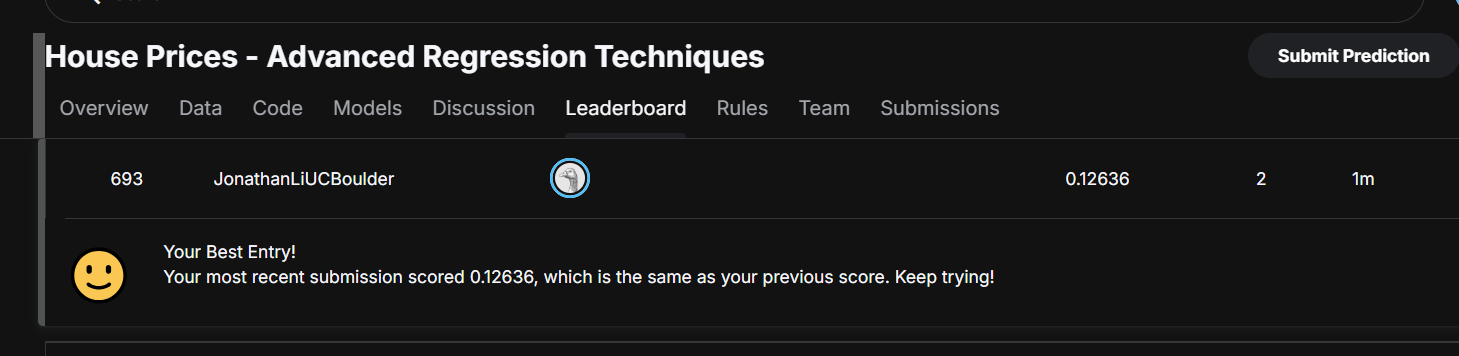

Looks like our model did well! XGBRegressor model was a good choice for a model as it's been proven to a strong model for regression tasks. XGBoost did most of the heavy lifting, but there are some takeaways and improvements to discuss. A takeaway is that the grid search helped balance the risk of overfitting vs underfitting because we had limited data size relative to the number of features. This ratio is something we have to be wary of in the future. Improvements can be made in feature engineering. We removed null values, collinear pairs and converted categories to numerical category codes. We could have done more in researching if some variables are just noise. We could have also looked into nonlinear relationships or skewed variables.

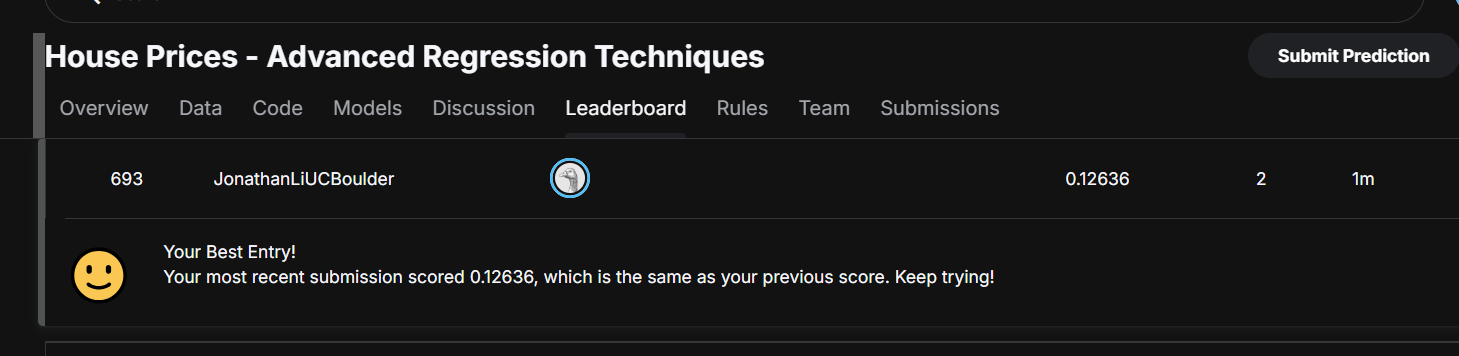
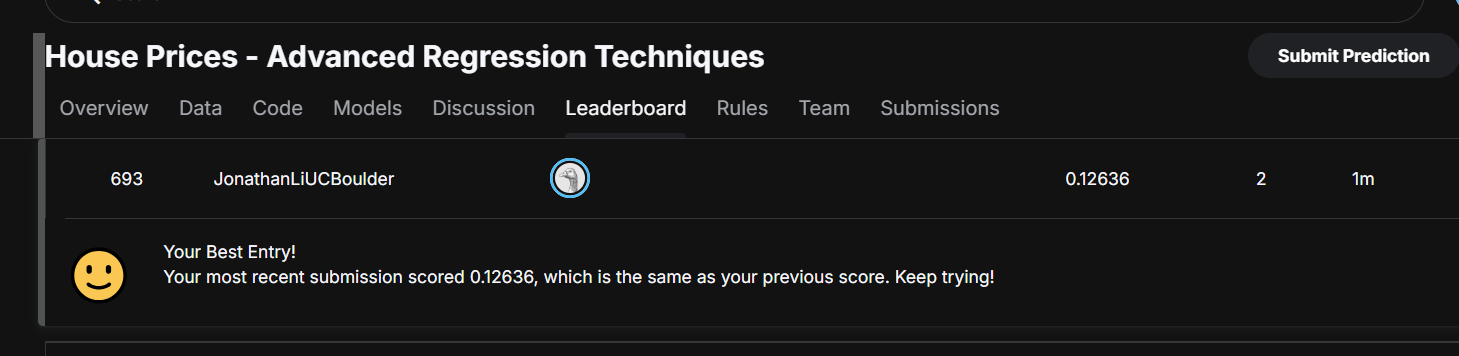

References:
https://xgboosting.com/most-important-xgboost-hyperparameters-to-tune/